In [2]:
import pandas as pd

df = pd.read_csv("credit_card_fraud_raw.csv")

print("Rows, Columns:", df.shape)
print("Column names:", df.columns.tolist())

df.head()

Rows, Columns: (10008, 31)
Column names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,28,-3.578324,2.080917,2.107002,-0.816965,0.866863,-0.348162,0.373614,-1.703893,0.887628,...,0.411746,0.289767,0.438865,-0.979886,-0.853716,-0.031832,-0.071016,0.173943,8.18,0
1,29,0.038032,1.071062,-2.219005,-0.018505,-2.230128,0.620406,-2.900907,0.517305,-2.094684,...,-0.008514,-0.179222,-0.639867,-0.236339,-0.631311,-0.353717,0.031948,-0.035342,113.31,0
2,76,5.822983,-2.477261,-0.222861,-2.451983,-0.644874,-0.556635,1.304870,-0.667838,-0.272808,...,0.534055,0.863000,-0.112053,-0.549556,-0.007978,0.145938,-0.113353,-0.169212,100.05,0
3,93,1.070711,0.915913,-0.616909,-2.848670,0.758940,-1.230565,0.331038,0.224496,-2.693499,...,-0.348803,0.541178,-1.069020,-0.559839,-0.986307,-0.375581,0.541791,0.617341,48.44,0
4,96,0.445722,-1.175183,-0.394847,0.815196,-2.599179,-0.918119,2.216113,-1.553073,-1.068054,...,0.178882,0.705493,0.215291,-0.052101,-0.692010,-0.024429,0.443022,-0.370235,3.90,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10008 entries, 0 to 10007
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    10008 non-null  int64  
 1   V1      10008 non-null  float64
 2   V2      10008 non-null  float64
 3   V3      10008 non-null  float64
 4   V4      10008 non-null  float64
 5   V5      10008 non-null  float64
 6   V6      10008 non-null  float64
 7   V7      10008 non-null  float64
 8   V8      10008 non-null  float64
 9   V9      10008 non-null  float64
 10  V10     10008 non-null  float64
 11  V11     10008 non-null  float64
 12  V12     10008 non-null  float64
 13  V13     10008 non-null  float64
 14  V14     10008 non-null  float64
 15  V15     10008 non-null  float64
 16  V16     10008 non-null  float64
 17  V17     10008 non-null  float64
 18  V18     10008 non-null  float64
 19  V19     10008 non-null  float64
 20  V20     10008 non-null  float64
 21  V21     10008 non-null  float64
 22  V22     1

In [5]:
import pandas as pd
from pathlib import Path

# Original file: cleaned output file
files = {
    "credit_card_fraud_raw.csv": "credit_card_fraud_cleaned.csv",
    "german_credit_data_raw.csv": "german_credit_data_cleaned.csv",
    "loan_prediction_raw.csv": "loan_prediction_cleaned.csv"
}

# Possible target column names in each dataset
target_names = {
    "credit_card_fraud_raw.csv": ["Class", "Fraud"],
    "german_credit_data_raw.csv": ["Risk", "Class", "Creditability"],
    "loan_prediction_raw.csv": ["Loan_Status", "LoanStatus"]
}

for input_file, output_file in files.items():

    if not Path(input_file).exists():
        print(f"File not found: {input_file}")
        continue

    # Read the CSV file
    df = pd.read_csv(input_file)

    # Remove extra spaces from column names
    df.columns = df.columns.str.strip()

    # Remove extra spaces from text values and mark empty text as missing
    text_columns = df.select_dtypes(include="object").columns
    for column in text_columns:
        df[column] = df[column].str.strip()
        df[column] = df[column].replace("", pd.NA)

    # Remove duplicate rows
    rows_before = len(df)
    df = df.drop_duplicates()
    duplicates_removed = rows_before - len(df)

    # Find the target column, if present
    target_column = None
    possible_targets = [name.lower() for name in target_names[input_file]]

    for column in df.columns:
        if column.lower() in possible_targets:
            target_column = column
            break

    # Remove rows where the target value is missing
    if target_column:
        df = df.dropna(subset=[target_column])

    # Fill missing numeric values with each column's median
    number_columns = df.select_dtypes(include="number").columns
    for column in number_columns:
        median_value = df[column].median()
        if pd.notna(median_value):
            df[column] = df[column].fillna(median_value)

    # Fill missing text values with the most common value
    text_columns = df.select_dtypes(include="object").columns
    for column in text_columns:
        common_value = df[column].mode(dropna=True)
        if len(common_value) > 0:
            df[column] = df[column].fillna(common_value[0])
        else:
            df[column] = df[column].fillna("Unknown")

    # Save the cleaned dataset as a new CSV file
    df.to_csv(output_file, index=False)

    print(f"\nFinished: {input_file}")
    print(f"Duplicate rows removed: {duplicates_removed}")
    print(f"Rows remaining: {len(df)}")
    print(f"Saved as: {output_file}")

print("\nAll three datasets have been processed.")


Finished: credit_card_fraud_raw.csv
Duplicate rows removed: 8
Rows remaining: 10000
Saved as: credit_card_fraud_cleaned.csv

Finished: german_credit_data_raw.csv
Duplicate rows removed: 0
Rows remaining: 1000
Saved as: german_credit_data_cleaned.csv

Finished: loan_prediction_raw.csv
Duplicate rows removed: 0
Rows remaining: 614
Saved as: loan_prediction_cleaned.csv

All three datasets have been processed.


C:\Users\soori\AppData\Local\Temp\ipykernel_22488\77271686.py:31: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns
C:\Users\soori\AppData\Local\Temp\ipykernel_22488\77271686.py:62: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/m

In [6]:
import pandas as pd

files = {
    "Credit Card Fraud": "credit_card_fraud_cleaned.csv",
    "German Credit": "german_credit_data_cleaned.csv",
    "Loan Prediction": "loan_prediction_cleaned.csv"
}

for dataset_name, file_name in files.items():
    print(f"\n{'=' * 50}")
    print(dataset_name)

    df = pd.read_csv(file_name)

    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("\nFirst 5 rows:")
    display(df.head())


Credit Card Fraud
Rows and columns: (10000, 31)
Column names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Missing values: 0
Duplicate rows: 0

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,28,-3.578324,2.080917,2.107002,-0.816965,0.866863,-0.348162,0.373614,-1.703893,0.887628,...,0.411746,0.289767,0.438865,-0.979886,-0.853716,-0.031832,-0.071016,0.173943,8.18,0
1,29,0.038032,1.071062,-2.219005,-0.018505,-2.230128,0.620406,-2.900907,0.517305,-2.094684,...,-0.008514,-0.179222,-0.639867,-0.236339,-0.631311,-0.353717,0.031948,-0.035342,113.31,0
2,76,5.822983,-2.477261,-0.222861,-2.451983,-0.644874,-0.556635,1.304870,-0.667838,-0.272808,...,0.534055,0.863000,-0.112053,-0.549556,-0.007978,0.145938,-0.113353,-0.169212,100.05,0
3,93,1.070711,0.915913,-0.616909,-2.848670,0.758940,-1.230565,0.331038,0.224496,-2.693499,...,-0.348803,0.541178,-1.069020,-0.559839,-0.986307,-0.375581,0.541791,0.617341,48.44,0
4,96,0.445722,-1.175183,-0.394847,0.815196,-2.599179,-0.918119,2.216113,-1.553073,-1.068054,...,0.178882,0.705493,0.215291,-0.052101,-0.692010,-0.024429,0.443022,-0.370235,3.90,0



German Credit
Rows and columns: (1000, 21)
Column names: ['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class']
Missing values: 0
Duplicate rows: 0

First 5 rows:


,Status_checking_account,Duration_months,Credit_history,Purpose,Credit_amount,Savings_account,Employment_since,Installment_rate_pct_income,Personal_status_sex,Other_debtors,...,Property,Age,Other_installment_plans,Housing,Existing_credits,Job,People_liable,Telephone,Foreign_worker,Class
0,A13,19,A34,A43,923,A64,A73,2,A93,A101,...,A122,25,A143,A152,2,A173,2,A191,A201,1
1,A12,5,A34,A43,7339,A61,A73,1,A93,A103,...,A121,31,A143,A153,1,A173,1,A192,A201,1
2,A11,15,A34,A42,2576,A61,A75,2,A93,A101,...,A122,26,A143,A152,1,A173,1,A191,A201,1
3,A14,10,A31,A42,1960,A61,A72,4,A92,A101,...,A123,39,A143,A152,1,A173,1,A192,A201,1
4,A12,9,A34,A46,5833,A61,A73,3,A92,A101,...,A124,27,A143,A151,1,A171,1,A191,A201,1



Loan Prediction
Rows and columns: (614, 13)
Column names: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']
Missing values: 0
Duplicate rows: 0

First 5 rows:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Female,No,0,Graduate,No,6462,1118,131.0,360.0,1.0,Semiurban,Y
1,LP001004,Male,No,2,Graduate,No,6163,0,373.0,360.0,1.0,Urban,Y
2,LP001006,Male,No,3+,Graduate,Yes,7098,1846,124.0,360.0,0.0,Urban,N
3,LP001009,Female,Yes,1,Not Graduate,No,9459,0,154.0,360.0,1.0,Urban,Y
4,LP001011,Male,No,1,Graduate,No,2511,0,119.0,360.0,0.0,Semiurban,N


In [7]:
import pandas as pd

files = {
    "Credit Card Fraud": "credit_card_fraud_cleaned.csv",
    "German Credit": "german_credit_data_cleaned.csv",
    "Loan Prediction": "loan_prediction_cleaned.csv"
}

for dataset_name, file_name in files.items():
    df = pd.read_csv(file_name)

    print(f"\n--- {dataset_name} ---")
    display(df.describe(include="all").T)


--- Credit Card Fraud ---


,count,mean,std,min,25%,50%,75%,max
Time,10000.0,85538.152200,49829.633280,28.000000,42220.000000,84786.000000,128417.500000,172742.000000
V1,10000.0,-0.008704,1.921566,-10.245089,-1.281583,-0.014316,1.288864,9.145338
V2,10000.0,0.021646,1.848257,-7.946691,-1.216910,0.018869,1.246858,9.040353
V3,10000.0,0.008356,1.806586,-6.935461,-1.205394,0.004446,1.218202,7.762106
V4,10000.0,-0.021256,1.743364,-6.556752,-1.178943,-0.026692,1.163682,6.719901
V5,10000.0,0.013697,1.674967,-7.435948,-1.090354,0.004243,1.130610,7.941831
V6,10000.0,-0.009109,1.615042,-6.501710,-1.092874,0.000892,1.084157,10.569908
V7,10000.0,-0.002072,1.561585,-8.455819,-1.038533,-0.002794,1.038466,7.227794
V8,10000.0,0.014466,1.475144,-7.069742,-0.969441,0.002400,0.995814,6.985186
V9,10000.0,0.016021,1.448844,-6.702438,-0.954773,0.007417,1.005287,6.537967



--- German Credit ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Status_checking_account,1000,4,A14,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration_months,1000.0,NaN,NaN,NaN,20.859,12.389698,4.0,12.0,18.5,27.0,72.0
Credit_history,1000,5,A32,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose,1000,10,A43,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit_amount,1000.0,NaN,NaN,NaN,3180.314,2501.470725,231.0,1481.25,2495.5,4056.5,19495.0
Savings_account,1000,5,A61,571,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment_since,1000,5,A73,355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installment_rate_pct_income,1000.0,NaN,NaN,NaN,2.904,1.118944,1.0,2.0,3.0,4.0,4.0
Personal_status_sex,1000,4,A93,575,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Other_debtors,1000,3,A101,889,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Loan Prediction ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,614,2,Male,495,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,614,2,Yes,393,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,614,4,0,361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,614,2,No,545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5688.394137,3489.376811,804.0,3284.25,4841.5,7043.75,30328.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1268.184039,2003.916833,0.0,0.0,569.5,1738.5,14677.0
LoanAmount,614.0,NaN,NaN,NaN,141.254072,70.858087,24.0,92.0,124.0,173.0,485.0
Loan_Amount_Term,614.0,NaN,NaN,NaN,340.944625,70.464459,12.0,360.0,360.0,360.0,480.0


In [8]:
import pandas as pd

files = {
    "Credit Card Fraud": (
        "credit_card_fraud_cleaned.csv",
        ["Class", "Fraud"]
    ),
    "German Credit": (
        "german_credit_data_cleaned.csv",
        ["Risk", "Class", "Creditability"]
    ),
    "Loan Prediction": (
        "loan_prediction_cleaned.csv",
        ["Loan_Status", "LoanStatus"]
    )
}

for dataset_name, (file_name, possible_targets) in files.items():
    df = pd.read_csv(file_name)

    target_column = next(
        (column for column in df.columns
         if column.lower() in [name.lower() for name in possible_targets]),
        None
    )

    print(f"\n--- {dataset_name} ---")

    if target_column:
        print("Target column:", target_column)
        print(df[target_column].value_counts(dropna=False))
    else:
        print("Target column not found.")
        print("Available columns:", df.columns.tolist())


--- Credit Card Fraud ---
Target column: Class
Class
0    9944
1      56
Name: count, dtype: int64

--- German Credit ---
Target column: Class
Class
1    766
2    234
Name: count, dtype: int64

--- Loan Prediction ---
Target column: Loan_Status
Loan_Status
Y    454
N    160
Name: count, dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("credit_card_fraud_cleaned.csv")

# "Class" அல்லது "Fraud" என்ற target column-ஐ கண்டுபிடிக்கிறது
target_column = next(
    (column for column in df.columns
     if column.lower() in ["class", "fraud"]),
    None
)

if target_column is None:
    print("Class/Fraud column கிடைக்கவில்லை.")
    print("உங்கள் columns:", df.columns.tolist())
else:
    counts = df[target_column].value_counts().sort_index()

    counts.plot(kind="bar", color=["steelblue", "tomato"])
    plt.title("Genuine and Fraud Transactions")
    plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
    plt.ylabel("Number of Transactions")
    plt.xticks(rotation=0)
    plt.show()

    print("Transaction counts:")
    print(counts)

ModuleNotFoundError: No module named 'matplotlib'

In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


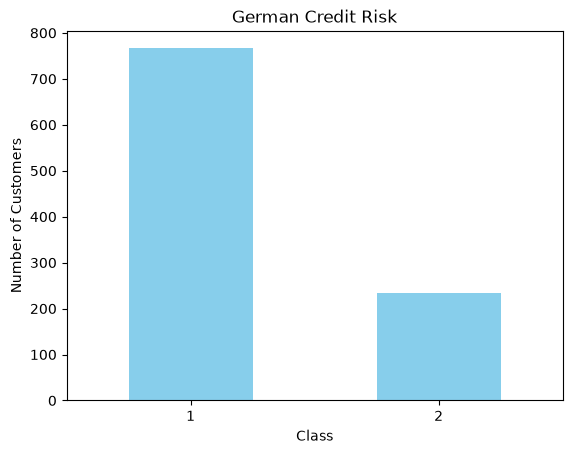

Class
1    766
2    234
Name: count, dtype: int64


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("german_credit_data_cleaned.csv")

# Risk அல்லது Class column-ஐத் தேடுகிறது
target_column = next(
    (column for column in df.columns
     if column.lower() in ["risk", "class", "creditability"]),
    None
)

if target_column is None:
    print("Risk/Class column கிடைக்கவில்லை.")
    print("Columns:", df.columns.tolist())
else:
    counts = df[target_column].value_counts()

    counts.plot(kind="bar", color="skyblue")
    plt.title("German Credit Risk")
    plt.xlabel(target_column)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=0)
    plt.show()

    print(counts)

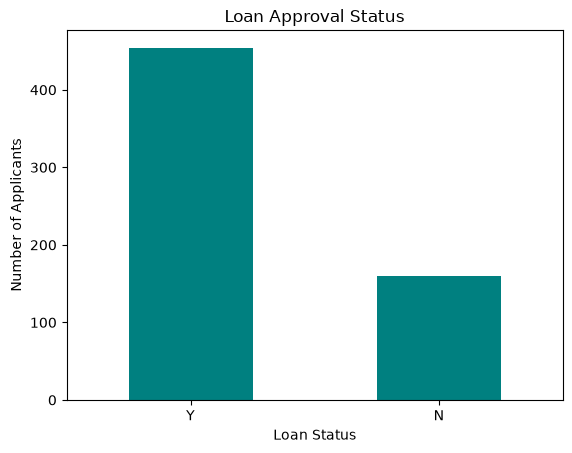

Loan_Status
Y    454
N    160
Name: count, dtype: int64


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("loan_prediction_cleaned.csv")

# Loan_Status என்ற column-ஐத் தேடுகிறது
target_column = next(
    (column for column in df.columns
     if column.lower() in ["loan_status", "loanstatus"]),
    None
)

if target_column is None:
    print("Loan_Status column கிடைக்கவில்லை.")
    print("Columns:", df.columns.tolist())
else:
    counts = df[target_column].value_counts()

    counts.plot(kind="bar", color="teal")
    plt.title("Loan Approval Status")
    plt.xlabel("Loan Status")
    plt.ylabel("Number of Applicants")
    plt.xticks(rotation=0)
    plt.show()

    print(counts)

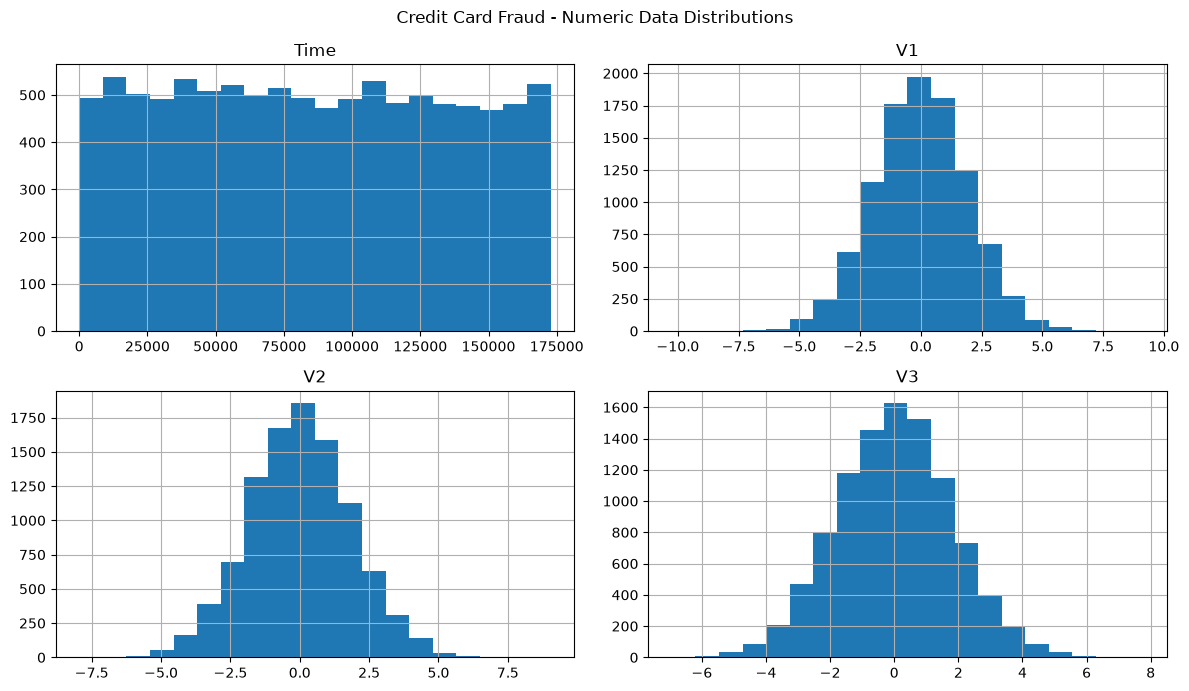

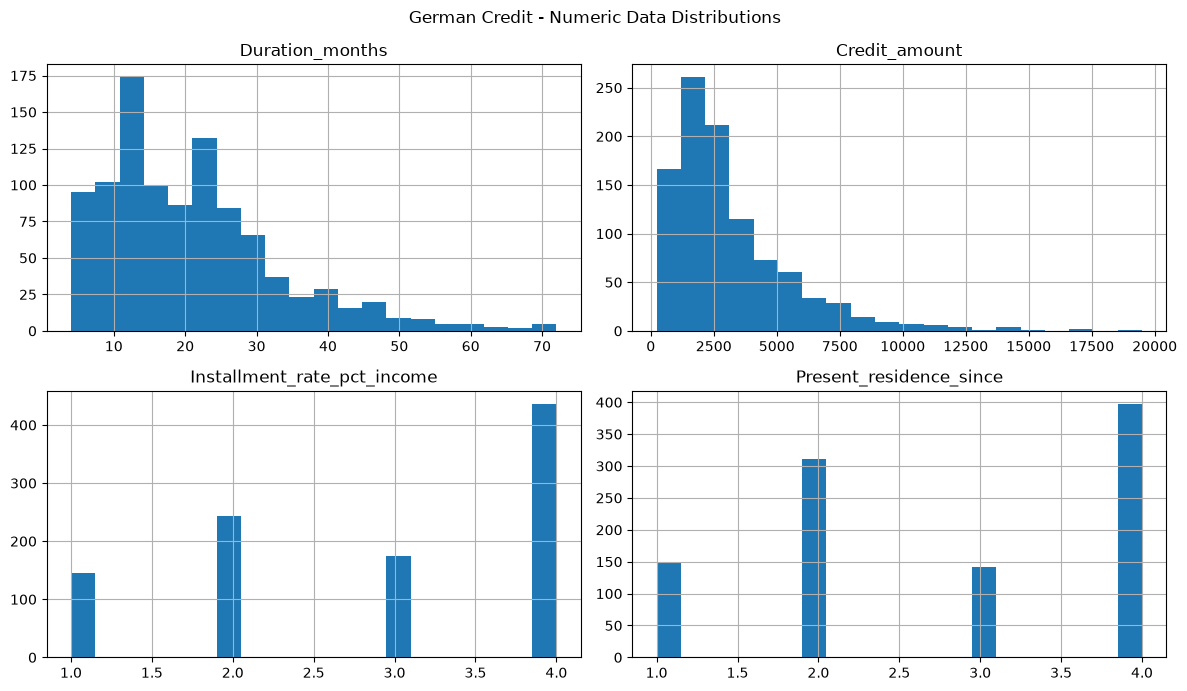

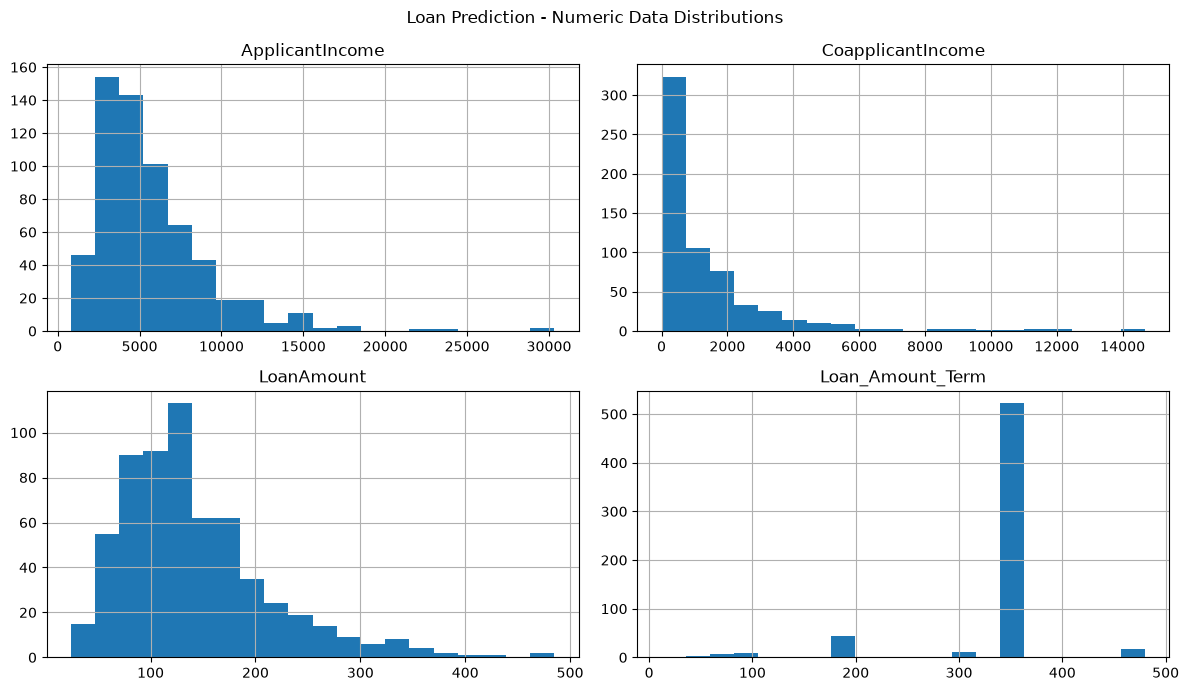

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

files = {
    "Credit Card Fraud": "credit_card_fraud_cleaned.csv",
    "German Credit": "german_credit_data_cleaned.csv",
    "Loan Prediction": "loan_prediction_cleaned.csv"
}

for dataset_name, file_name in files.items():
    df = pd.read_csv(file_name)

    numeric_columns = df.select_dtypes(include="number").columns.tolist()

    # Chart-களை எளிமையாக வைத்திருக்க முதல் 4 numeric columns மட்டும்
    columns_to_plot = numeric_columns[:4]

    if not columns_to_plot:
        print(f"{dataset_name}: numeric columns இல்லை.")
        continue

    df[columns_to_plot].hist(figsize=(12, 7), bins=20)
    plt.suptitle(f"{dataset_name} - Numeric Data Distributions")
    plt.tight_layout()
    plt.show()

In [1]:
from pathlib import Path

for file in [
    "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv"
]:
    print(file, "உருவாகியுள்ளது:", Path(file).exists())

credit_card_fraud_cleaned.csv உருவாகியுள்ளது: True
german_credit_data_cleaned.csv உருவாகியுள்ளது: True
loan_prediction_cleaned.csv உருவாகியுள்ளது: True


In [2]:
import pandas as pd

files = [
    "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv"
]

for file in files:
    df = pd.read_csv(file)

    print(f"\n{file}")
    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


credit_card_fraud_cleaned.csv
Rows and columns: (10000, 31)
Missing values: 0
Duplicate rows: 0

german_credit_data_cleaned.csv
Rows and columns: (1000, 21)
Missing values: 0
Duplicate rows: 0

loan_prediction_cleaned.csv
Rows and columns: (614, 13)
Missing values: 0
Duplicate rows: 0


In [3]:
import pandas as pd

files = [
    "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv"
]

for file in files:
    df = pd.read_csv(file)

    print(f"\n--- {file} ---")
    print("Columns:", df.columns.tolist())
    display(df.head())


--- credit_card_fraud_cleaned.csv ---
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,28,-3.578324,2.080917,2.107002,-0.816965,0.866863,-0.348162,0.373614,-1.703893,0.887628,...,0.411746,0.289767,0.438865,-0.979886,-0.853716,-0.031832,-0.071016,0.173943,8.18,0
1,29,0.038032,1.071062,-2.219005,-0.018505,-2.230128,0.620406,-2.900907,0.517305,-2.094684,...,-0.008514,-0.179222,-0.639867,-0.236339,-0.631311,-0.353717,0.031948,-0.035342,113.31,0
2,76,5.822983,-2.477261,-0.222861,-2.451983,-0.644874,-0.556635,1.304870,-0.667838,-0.272808,...,0.534055,0.863000,-0.112053,-0.549556,-0.007978,0.145938,-0.113353,-0.169212,100.05,0
3,93,1.070711,0.915913,-0.616909,-2.848670,0.758940,-1.230565,0.331038,0.224496,-2.693499,...,-0.348803,0.541178,-1.069020,-0.559839,-0.986307,-0.375581,0.541791,0.617341,48.44,0
4,96,0.445722,-1.175183,-0.394847,0.815196,-2.599179,-0.918119,2.216113,-1.553073,-1.068054,...,0.178882,0.705493,0.215291,-0.052101,-0.692010,-0.024429,0.443022,-0.370235,3.90,0



--- german_credit_data_cleaned.csv ---
Columns: ['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class']


,Status_checking_account,Duration_months,Credit_history,Purpose,Credit_amount,Savings_account,Employment_since,Installment_rate_pct_income,Personal_status_sex,Other_debtors,...,Property,Age,Other_installment_plans,Housing,Existing_credits,Job,People_liable,Telephone,Foreign_worker,Class
0,A13,19,A34,A43,923,A64,A73,2,A93,A101,...,A122,25,A143,A152,2,A173,2,A191,A201,1
1,A12,5,A34,A43,7339,A61,A73,1,A93,A103,...,A121,31,A143,A153,1,A173,1,A192,A201,1
2,A11,15,A34,A42,2576,A61,A75,2,A93,A101,...,A122,26,A143,A152,1,A173,1,A191,A201,1
3,A14,10,A31,A42,1960,A61,A72,4,A92,A101,...,A123,39,A143,A152,1,A173,1,A192,A201,1
4,A12,9,A34,A46,5833,A61,A73,3,A92,A101,...,A124,27,A143,A151,1,A171,1,A191,A201,1



--- loan_prediction_cleaned.csv ---
Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Female,No,0,Graduate,No,6462,1118,131.0,360.0,1.0,Semiurban,Y
1,LP001004,Male,No,2,Graduate,No,6163,0,373.0,360.0,1.0,Urban,Y
2,LP001006,Male,No,3+,Graduate,Yes,7098,1846,124.0,360.0,0.0,Urban,N
3,LP001009,Female,Yes,1,Not Graduate,No,9459,0,154.0,360.0,1.0,Urban,Y
4,LP001011,Male,No,1,Graduate,No,2511,0,119.0,360.0,0.0,Semiurban,N


In [4]:
import pandas as pd

files = [
    "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv"
]

summary = []

for file in files:
    df = pd.read_csv(file)

    summary.append({
        "Dataset": file,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,credit_card_fraud_cleaned.csv,10000,31,0,0
1,german_credit_data_cleaned.csv,1000,21,0,0
2,loan_prediction_cleaned.csv,614,13,0,0


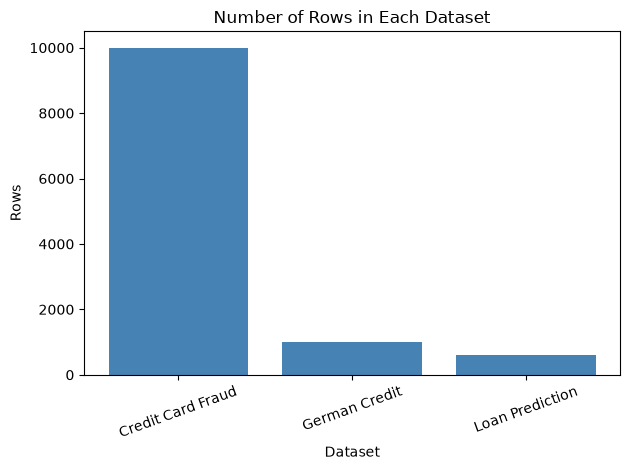

{'Credit Card Fraud': 10000, 'German Credit': 1000, 'Loan Prediction': 614}


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

files = {
    "Credit Card Fraud": "credit_card_fraud_cleaned.csv",
    "German Credit": "german_credit_data_cleaned.csv",
    "Loan Prediction": "loan_prediction_cleaned.csv"
}

row_counts = {}

for name, file in files.items():
    df = pd.read_csv(file)
    row_counts[name] = len(df)

plt.bar(row_counts.keys(), row_counts.values(), color="steelblue")
plt.title("Number of Rows in Each Dataset")
plt.xlabel("Dataset")
plt.ylabel("Rows")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(row_counts)

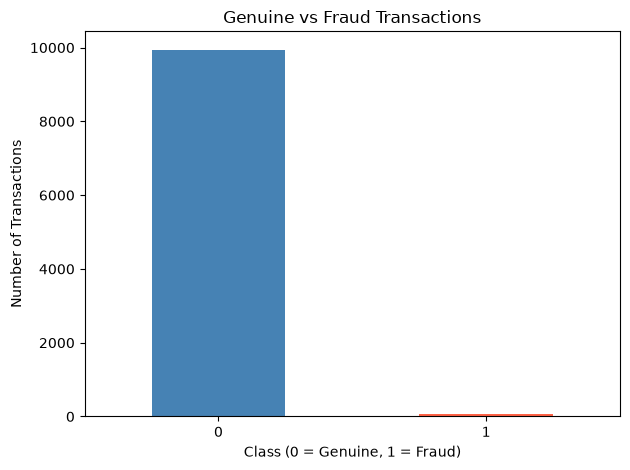

Transaction counts:
Class
0    9944
1      56
Name: count, dtype: int64


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("credit_card_fraud_cleaned.csv")

counts = df["Class"].value_counts().sort_index()

counts.plot(kind="bar", color=["steelblue", "tomato"])

plt.title("Genuine vs Fraud Transactions")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Transaction counts:")
print(counts)

In [8]:
import pandas as pd

df = pd.read_csv("german_credit_data_cleaned.csv")

print(df.columns.tolist())

['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class']


In [9]:
import pandas as pd

df = pd.read_csv("german_credit_data_cleaned.csv")
print(df.columns.tolist())

['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class']


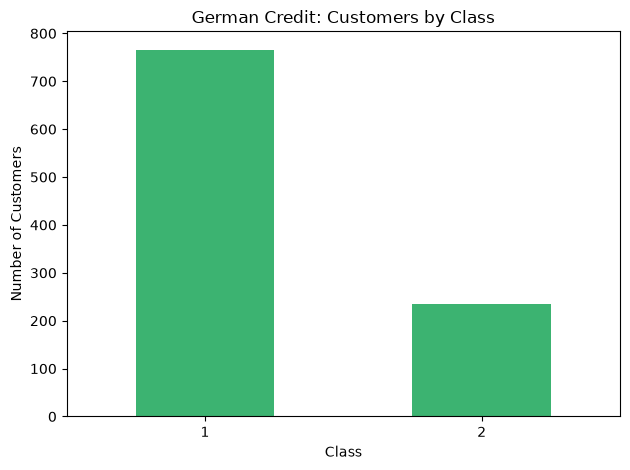

Class
1    766
2    234
Name: count, dtype: int64


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("german_credit_data_cleaned.csv")

counts = df["Class"].value_counts()

counts.plot(kind="bar", color="mediumseagreen")

plt.title("German Credit: Customers by Class")
plt.xlabel("Class")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(counts)

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("loan_prediction_cleaned.csv")

print("Columns:", df.columns.tolist())

Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


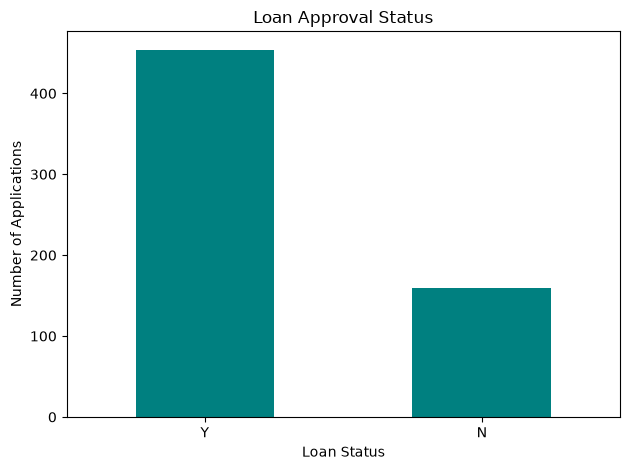

Loan_Status
Y    454
N    160
Name: count, dtype: int64


In [12]:
counts = df["Loan_Status"].value_counts()

counts.plot(kind="bar", color="teal")
plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(counts)

In [13]:
import pandas as pd

df = pd.read_csv("loan_prediction_cleaned.csv")
print(df.columns.tolist())

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


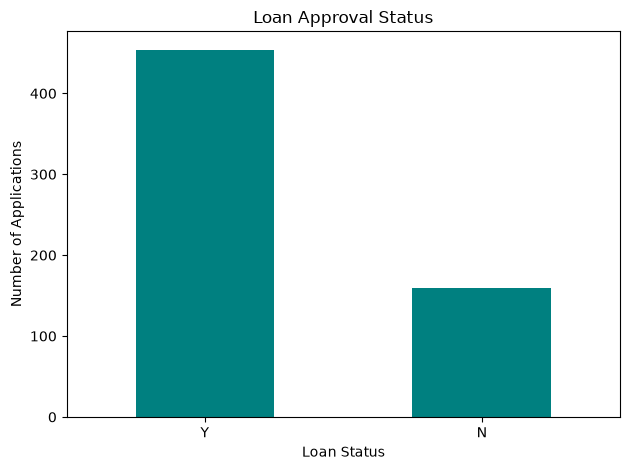

Loan_Status
Y    454
N    160
Name: count, dtype: int64


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("loan_prediction_cleaned.csv")

counts = df["Loan_Status"].value_counts()

counts.plot(kind="bar", color="teal")
plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(counts)

In [15]:
import pandas as pd

df = pd.read_csv("credit_card_fraud_cleaned.csv")

fraud_count = (df["Class"] == 1).sum()
total_count = len(df)
fraud_percentage = (fraud_count / total_count) * 100

print("Total transactions:", total_count)
print("Fraud transactions:", fraud_count)
print(f"Fraud percentage: {fraud_percentage:.2f}%")

Total transactions: 10000
Fraud transactions: 56
Fraud percentage: 0.56%


In [16]:
import pandas as pd

df = pd.read_csv("loan_prediction_cleaned.csv")

print("Loan approval counts:")
print(df["Loan_Status"].value_counts())

print("\nLoan approval percentages:")
print((df["Loan_Status"].value_counts(normalize=True) * 100).round(2))

Loan approval counts:
Loan_Status
Y    454
N    160
Name: count, dtype: int64

Loan approval percentages:
Loan_Status
Y    73.94
N    26.06
Name: proportion, dtype: float64


In [17]:
import pandas as pd

df = pd.read_csv("loan_prediction_cleaned.csv")

average_income = df["ApplicantIncome"].mean()
average_loan = df["LoanAmount"].mean()

print(f"Average applicant income: {average_income:.2f}")
print(f"Average loan amount: {average_loan:.2f}")

Average applicant income: 5688.39
Average loan amount: 141.25


In [18]:
import pandas as pd

df = pd.read_csv("loan_prediction_cleaned.csv")

income_by_status = df.groupby("Loan_Status")["ApplicantIncome"].mean()

print("Average applicant income by loan status:")
print(income_by_status)

Average applicant income by loan status:
Loan_Status
N    5388.31250
Y    5794.14978
Name: ApplicantIncome, dtype: float64


In [19]:
from pathlib import Path
import pandas as pd

files = [
    "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv"
]

for file in files:
    if Path(file).exists():
        df = pd.read_csv(file)
        print(f"\n{file}: கிடைத்தது")
        print("Rows:", len(df))
        print("Missing values:", df.isnull().sum().sum())
        print("Duplicate rows:", df.duplicated().sum())
    else:
        print(f"\n{file}: இல்லை - cleaning code-ஐ இயக்கவும்")


credit_card_fraud_cleaned.csv: கிடைத்தது
Rows: 10000
Missing values: 0
Duplicate rows: 0

german_credit_data_cleaned.csv: கிடைத்தது
Rows: 1000
Missing values: 0
Duplicate rows: 0

loan_prediction_cleaned.csv: கிடைத்தது
Rows: 614
Missing values: 0
Duplicate rows: 0


In [20]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:


import pandas as pd

datasets = {
    "Credit Card Fraud": "credit_card_fraud_cleaned.csv",
    "German Credit": "german_credit_data_cleaned.csv",
    "Loan Prediction": "loan_prediction_cleaned.csv"
}

with pd.ExcelWriter("cleaned_datasets.xlsx", engine="openpyxl") as writer:
    for sheet_name, file_name in datasets.items():
        df = pd.read_csv(file_name)
        df.to_excel(writer, sheet_name=sheet_name, index=False)

print("Saved as cleaned_datasets.xlsx")

Saved as cleaned_datasets.xlsx


In [22]:
import pandas as pd

files = {
    "credit_card_fraud_cleaned.csv": "credit_card_fraud_cleaned.csv",
    "german_credit_data_cleaned.csv": "german_credit_data_cleaned.csv",
    "loan_prediction_cleaned.csv": "loan_prediction_cleaned.csv"
}

for input_file, output_file in files.items():
    df = pd.read_csv(input_file)
    df.to_csv(output_file, index=False)
    print(f"Saved: {output_file}")

Saved: credit_card_fraud_cleaned.csv
Saved: german_credit_data_cleaned.csv
Saved: loan_prediction_cleaned.csv


In [24]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Read the cleaned datasets
fraud = pd.read_csv("credit_card_fraud_cleaned.csv")
german = pd.read_csv("german_credit_data_cleaned.csv")
loan = pd.read_csv("loan_prediction_cleaned.csv")

# Print column names so you can confirm them
print("Fraud columns:", fraud.columns.tolist())
print("German credit columns:", german.columns.tolist())
print("Loan columns:", loan.columns.tolist())

# Average applicant income and average loan amount
if "ApplicantIncome" in loan.columns:
    print("\nAverage applicant income:", round(loan["ApplicantIncome"].mean(), 2))

if "LoanAmount" in loan.columns:
    print("Average loan amount:", round(loan["LoanAmount"].mean(), 2))

# Fraud percentage
if "Class" in fraud.columns:
    fraud_percentage = (fraud["Class"] == 1).mean() * 100
    print(f"\nFraud percentage: {fraud_percentage:.2f}%")

# Default percentage, only if a default column exists
default_column = next(
    (col for col in german.columns
     if col.lower() in ["default", "loan_default"]),
    None
)

if default_column:
    print("\nDefault values:")
    print(german[default_column].value_counts(normalize=True).mul(100).round(2))
else:
    print("\nDefault percentage: no Default column found in German Credit dataset.")
    print("German dataset target column is:", "Class" if "Class" in german.columns else "not found")

Fraud columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
German credit columns: ['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class']
Loan columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Average applicant income: 5688.39
Average loan amount: 141.25

Fraud percentage: 0.56%

Default percentage: no Default column found in German Credit dataset.
Ge

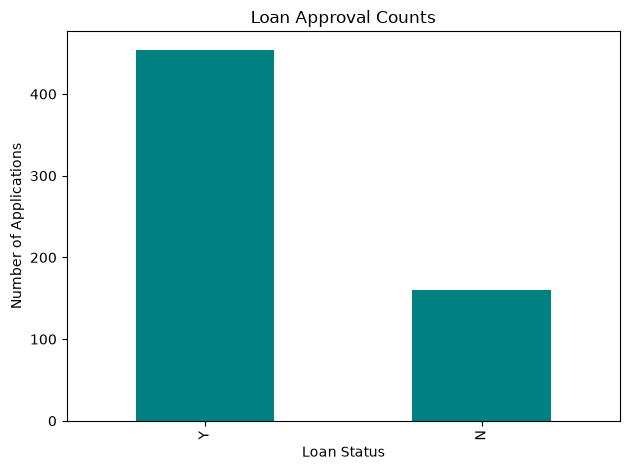

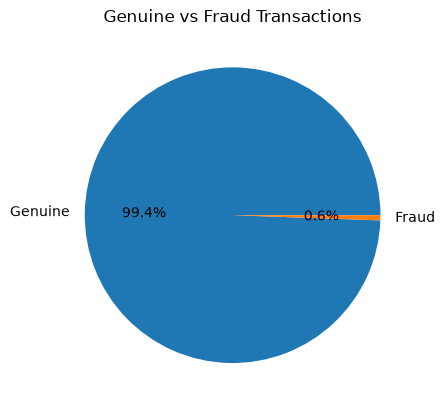

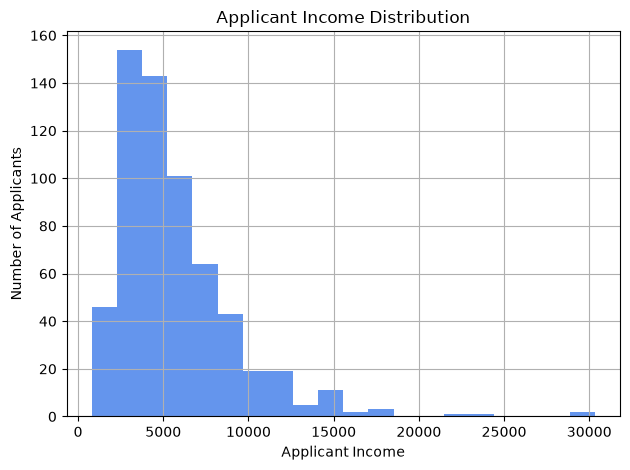

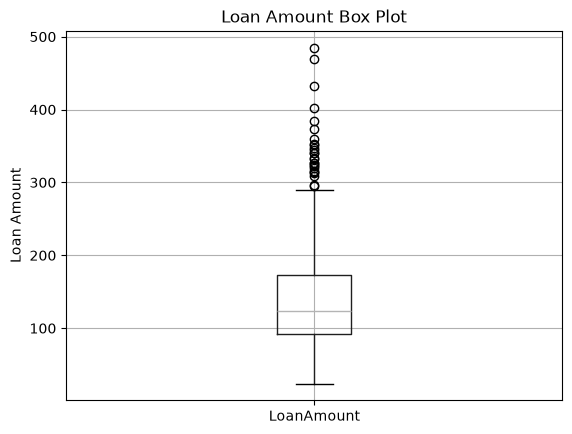

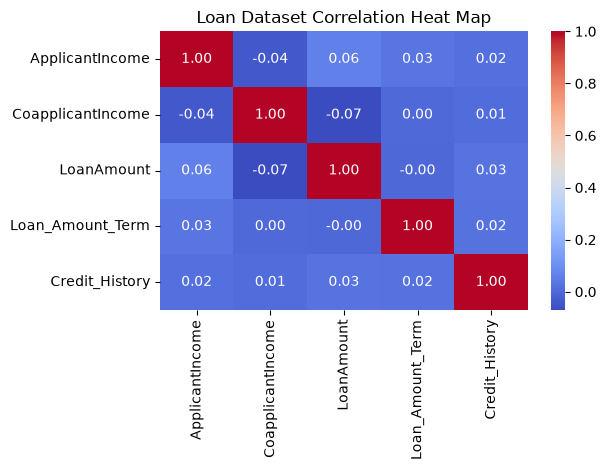

In [26]:

# 1. Bar chart: Loan approval counts
if "Loan_Status" in loan.columns:
    loan["Loan_Status"].value_counts().plot(
        kind="bar", color="teal", title="Loan Approval Counts"
    )
    plt.xlabel("Loan Status")
    plt.ylabel("Number of Applications")
    plt.tight_layout()
    plt.show()

# 2. Pie chart: Genuine vs fraud transactions
if "Class" in fraud.columns:
    fraud["Class"].value_counts().plot(
        kind="pie",
        autopct="%1.1f%%",
        labels=["Genuine", "Fraud"],
        title="Genuine vs Fraud Transactions"
    )
    plt.ylabel("")
    plt.show()

# 3. Histogram: Applicant income
if "ApplicantIncome" in loan.columns:
    loan["ApplicantIncome"].hist(bins=20, color="cornflowerblue")
    plt.title("Applicant Income Distribution")
    plt.xlabel("Applicant Income")
    plt.ylabel("Number of Applicants")
    plt.tight_layout()
    plt.show()

# 4. Box plot: Loan amount
if "LoanAmount" in loan.columns:
    loan.boxplot(column="LoanAmount")
    plt.title("Loan Amount Box Plot")
    plt.ylabel("Loan Amount")
    plt.show()

# 5. Heat map: Numeric columns in the loan dataset
numeric_loan = loan.select_dtypes(include="number")

if len(numeric_loan.columns) > 1:
    sns.heatmap(numeric_loan.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Loan Dataset Correlation Heat Map")
    plt.tight_layout()
    plt.show()

In [27]:
import pandas as pd

# Load the cleaned datasets
fraud = pd.read_csv("credit_card_fraud_cleaned.csv")
german = pd.read_csv("german_credit_data_cleaned.csv")
loan = pd.read_csv("loan_prediction_cleaned.csv")

# 1. Loan dataset: create Income and Debt Ratio features
loan["Total_Income"] = loan["ApplicantIncome"] + loan["CoapplicantIncome"]

# LoanAmount may be recorded in thousands, so use it as given here.
loan["Debt_Ratio"] = loan["LoanAmount"] / loan["Total_Income"].replace(0, pd.NA)

# Divide applicants into income groups
loan["Income_Group"] = pd.cut(
    loan["Total_Income"],
    bins=[-1, 3000, 6000, 10000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

# 2. German Credit dataset: create a simple risk flag from Class
# This assumes Class contains the values 1 and 2, where 1 is good and 2 is bad.
# Confirm your dataset's Class meaning before using this for analysis.
if "Class" in german.columns:
    german["High_Risk_Customer"] = german["Class"].astype(str).str.strip().isin(["2", "Bad", "bad"]).astype(int)

# 3. Fraud dataset: create a fraud risk flag from Class
# In the common format, Class 1 means fraud and 0 means genuine.
if "Class" in fraud.columns:
    fraud["High_Risk_Customer"] = (fraud["Class"] == 1).astype(int)

# Transaction Hour and Weekend Transaction need a real date/time column.
# The Time column in your screenshot is elapsed seconds, not a date or clock time,
# so we cannot correctly derive hour or weekend from it.
# These features will be created only if a transaction timestamp column exists.
date_column = next(
    (column for column in fraud.columns
     if column.lower() in ["timestamp", "transaction_date", "datetime", "date"]),
    None
)

if date_column:
    fraud[date_column] = pd.to_datetime(fraud[date_column], errors="coerce")
    fraud["Transaction_Hour"] = fraud[date_column].dt.hour
    fraud["Weekend_Transaction"] = (
        fraud[date_column].dt.dayofweek >= 5
    ).astype("Int64")

# Save feature-engineered datasets as new files
loan.to_csv("loan_prediction_features.csv", index=False)
german.to_csv("german_credit_features.csv", index=False)
fraud.to_csv("credit_card_fraud_features.csv", index=False)

print("Feature engineering complete.")
print("Saved: loan_prediction_features.csv")
print("Saved: german_credit_features.csv")
print("Saved: credit_card_fraud_features.csv")

print("\nLoan dataset columns:")
print(loan.columns.tolist())

print("\nGerman Credit dataset columns:")
print(german.columns.tolist())

print("\nFraud dataset columns:")
print(fraud.columns.tolist())

Feature engineering complete.
Saved: loan_prediction_features.csv
Saved: german_credit_features.csv
Saved: credit_card_fraud_features.csv

Loan dataset columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Total_Income', 'Debt_Ratio', 'Income_Group']

German Credit dataset columns:
['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class', 'High_Risk_Customer']

Fraud dataset columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V2

In [28]:
print("Loan features:")
display(loan[["Total_Income", "Debt_Ratio", "Income_Group"]].head())

print("German Credit feature:")
if "High_Risk_Customer" in german.columns:
    display(german[["Class", "High_Risk_Customer"]].head())

print("Fraud feature:")
if "High_Risk_Customer" in fraud.columns:
    display(fraud[["Class", "High_Risk_Customer"]].head())

print("Fraud time columns:")
print([
    column for column in fraud.columns
    if column in ["Transaction_Hour", "Weekend_Transaction"]
])

Loan features:


,Total_Income,Debt_Ratio,Income_Group
0,7580,0.017282,High
1,6163,0.060522,High
2,8944,0.013864,High
3,9459,0.016281,High
4,2511,0.047391,Low


German Credit feature:


,Class,High_Risk_Customer
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


Fraud feature:


,Class,High_Risk_Customer
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


Fraud time columns:
[]


Average Amount by Class:
Class
0    77.553723
1    54.685893
Name: Amount, dtype: float64


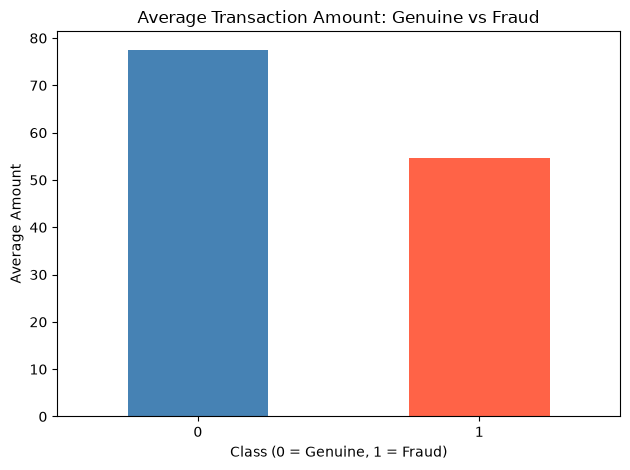

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

fraud = pd.read_csv("credit_card_fraud_features.csv")

# Average transaction amount by Class
average_amount = fraud.groupby("Class")["Amount"].mean()

print("Average Amount by Class:")
print(average_amount)

average_amount.plot(kind="bar", color=["steelblue", "tomato"])
plt.title("Average Transaction Amount: Genuine vs Fraud")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Average Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Loan_Status    N    Y
Income_Group         
High          51  153
Low           23   40
Medium        62  176
Very High     24   85


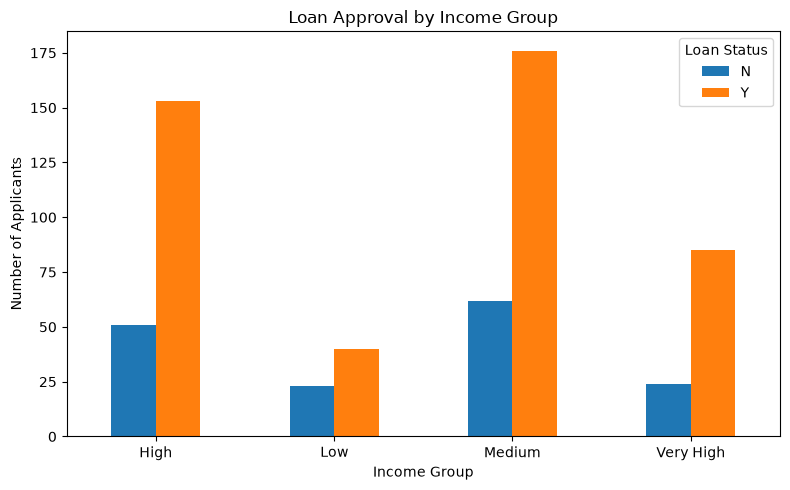

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

loan = pd.read_csv("loan_prediction_features.csv")

approval_by_income = pd.crosstab(
    loan["Income_Group"],
    loan["Loan_Status"]
)

print(approval_by_income)

approval_by_income.plot(kind="bar", figsize=(8, 5))
plt.title("Loan Approval by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

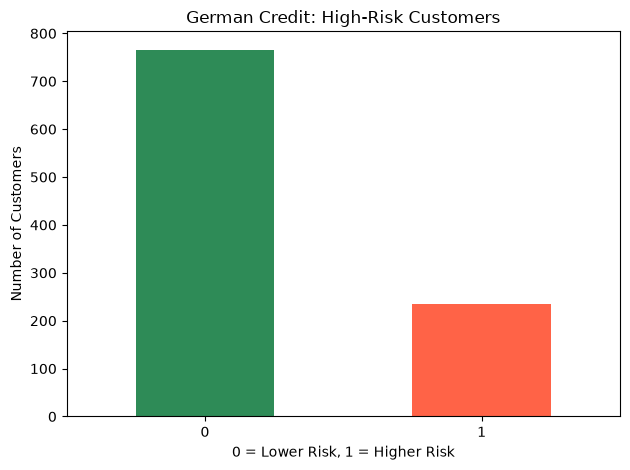

High_Risk_Customer
0    766
1    234
Name: count, dtype: int64


In [31]:
import pandas as pd
import matplotlib.pyplot as plt

german = pd.read_csv("german_credit_features.csv")

risk_counts = german["High_Risk_Customer"].value_counts().sort_index()

risk_counts.plot(kind="bar", color=["seagreen", "tomato"])
plt.title("German Credit: High-Risk Customers")
plt.xlabel("0 = Lower Risk, 1 = Higher Risk")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(risk_counts)

In [32]:
import pandas as pd

files = {
    "Credit Card Fraud": "credit_card_fraud_features.csv",
    "German Credit": "german_credit_features.csv",
    "Loan Prediction": "loan_prediction_features.csv"
}

for name, file_name in files.items():
    df = pd.read_csv(file_name)

    print(f"\n--- {name} ---")
    print("Rows and columns:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", df.columns.tolist())


--- Credit Card Fraud ---
Rows and columns: (10000, 32)
Missing values: 0
Duplicate rows: 0
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'High_Risk_Customer']

--- German Credit ---
Rows and columns: (1000, 22)
Missing values: 0
Duplicate rows: 0
Columns: ['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class', 'High_Risk_Customer']

--- Loan Prediction ---
Rows and columns: (614, 16)
Missing values: 0
Duplicate rows: 0
Columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employe

In [34]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 731.4 kB/s eta 0:00:11
   -- ------------------------------------- 0.5/8.4 MB 731.4 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.4 MB 804.3 kB/s eta 0:00:10
   ----- ---------------------------------- 1.0/8.4 MB 852.2 kB/s eta 0:00:09
   ------ --------------------------------- 1.3/8.4 MB 943.6 kB/s eta 0:00:08
   ------- -------------------------------- 1.6/8.4 MB 936.1 kB/s eta 0:00:08
   -------- ------------------------------- 1.8/8.4 MB 980.7 kB/s eta 0:00:07
   ---------- ----------------------------- 2.1/8.4 MB 1.0 MB/s eta 0:00:07
   ------------ --------------------------- 2.6/8.4 MB 1.1 MB/s eta 0:00:06
   ------------- ---------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load the feature-engineered loan dataset
loan = pd.read_csv("loan_prediction_features.csv")

# Remove rows where the answer (Loan_Status) is missing
loan = loan.dropna(subset=["Loan_Status"])

# Separate input columns (X) and answer column (y)
X = loan.drop(columns=["Loan_Status", "Loan_ID"], errors="ignore")
y = loan["Loan_Status"]

# Identify numeric and text columns
numeric_columns = X.select_dtypes(include="number").columns
text_columns = X.select_dtypes(exclude="number").columns

# Fill missing values and convert text categories to numbers
preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", SimpleImputer(strategy="median"), numeric_columns),
        (
            "categories",
            Pipeline(steps=[
                ("fill_missing", SimpleImputer(strategy="most_frequent")),
                ("make_numbers", OneHotEncoder(handle_unknown="ignore"))
            ]),
            text_columns
        )
    ]
)

# Build the model
model = Pipeline(steps=[
    ("prepare_data", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Keep some rows for checking model performance
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train and evaluate
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nClassification report:")
print(classification_report(y_test, predictions))

Accuracy: 0.748

Classification report:
              precision    recall  f1-score   support

           N       0.52      0.38      0.44        32
           Y       0.80      0.88      0.84        91

    accuracy                           0.75       123
   macro avg       0.66      0.63      0.64       123
weighted avg       0.73      0.75      0.73       123



In [36]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


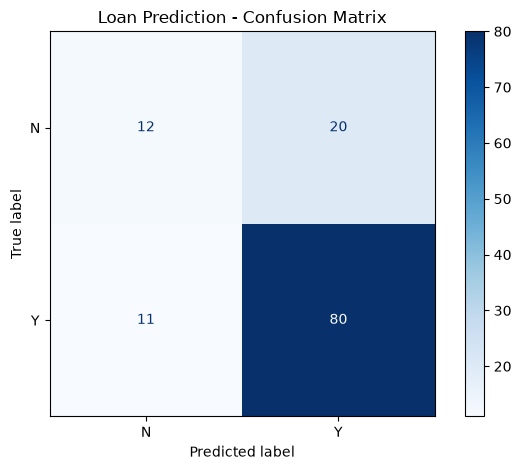

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    cmap="Blues"
)

plt.title("Loan Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Classes:", model.classes_)
print("Precision:", precision_score(y_test, predictions, average="weighted", zero_division=0))
print("Recall:", recall_score(y_test, predictions, average="weighted", zero_division=0))
print("F1-score:", f1_score(y_test, predictions, average="weighted", zero_division=0))

Classes: ['N' 'Y']
Precision: 0.7276069282431955
Recall: 0.7479674796747967
F1-score: 0.7332845760632761


In [39]:
import pandas as pd

for file in [
    "loan_prediction_features.csv",
    "german_credit_features.csv",
    "credit_card_fraud_features.csv"
]:
    df = pd.read_csv(file)
    print(f"\n{file}")
    print(df.columns.tolist())


loan_prediction_features.csv
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status', 'Total_Income', 'Debt_Ratio', 'Income_Group']

german_credit_features.csv
['Status_checking_account', 'Duration_months', 'Credit_history', 'Purpose', 'Credit_amount', 'Savings_account', 'Employment_since', 'Installment_rate_pct_income', 'Personal_status_sex', 'Other_debtors', 'Present_residence_since', 'Property', 'Age', 'Other_installment_plans', 'Housing', 'Existing_credits', 'Job', 'People_liable', 'Telephone', 'Foreign_worker', 'Class', 'High_Risk_Customer']

credit_card_fraud_features.csv
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'High_Risk_Customer']


In [40]:
from pathlib import Path

files = [
    "loan_prediction_features.csv",
    "german_credit_features.csv",
    "credit_card_fraud_features.csv"
]

for file in files:
    print(file, Path(file).exists())

loan_prediction_features.csv True
german_credit_features.csv True
credit_card_fraud_features.csv True


In [41]:
import pandas as pd

german = pd.read_csv("german_credit_features.csv")

print("Class values:")
print(german["Class"].value_counts(dropna=False))

print("\nData types:")
print(german["Class"].dtype)

Class values:
Class
1    766
2    234
Name: count, dtype: int64

Data types:
int64


In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split

german = pd.read_csv("german_credit_features.csv")

# Class 1 = Good credit (0); Class 2 = Bad credit (1)
X = german.drop(columns=["Class", "High_Risk_Customer"], errors="ignore")
y = (german["Class"] == 2).astype(int)

# Training data: model கற்றுக்கொள்ள
# Testing data: model-ஐச் சரிபார்க்க
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Risky customers in training data:", y_train.sum())
print("Risky customers in testing data:", y_test.sum())

Training rows: 800
Testing rows: 200
Risky customers in training data: 187
Risky customers in testing data: 47


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Separate number and text columns
numeric_columns = X_train.select_dtypes(include="number").columns
text_columns = X_train.select_dtypes(exclude="number").columns

# Prepare missing values and text categories
preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", Pipeline([
            ("fill_missing", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric_columns),

        ("text", Pipeline([
            ("fill_missing", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore"))
        ]), text_columns)
    ]
)

# Three models to compare
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced", max_depth=5
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced"
    )
}

results = []

for name, classifier in models.items():
    model = Pipeline([
        ("prepare_data", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

    print(name, "trained")

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results_df.round(3))

Logistic Regression trained
Decision Tree trained
Random Forest trained


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.64,0.342,0.574,0.429
1,Decision Tree,0.66,0.302,0.340,0.320
2,Random Forest,0.72,0.345,0.213,0.263


In [44]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import pandas as pd

# Logistic Regression model-ஐ மீண்டும் train செய்கிறது
risk_model = Pipeline([
    ("prepare_data", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

risk_model.fit(X_train, y_train)

# Bad credit (Class 2) வாய்ப்பு
bad_credit_probability = risk_model.predict_proba(X_test)[:, 1]

# Example risk bands
risk_category = pd.cut(
    bad_credit_probability,
    bins=[-0.01, 0.25, 0.50, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

# Show actual and predicted risk for test rows
risk_results = X_test.copy()
risk_results["Actual_Bad_Credit"] = y_test
risk_results["Bad_Credit_Probability"] = bad_credit_probability
risk_results["Risk_Category"] = risk_category

display(risk_results.head(10))

print("\nRisk category counts:")
print(risk_results["Risk_Category"].value_counts())

,Status_checking_account,Duration_months,Credit_history,Purpose,Credit_amount,Savings_account,Employment_since,Installment_rate_pct_income,Personal_status_sex,Other_debtors,...,Other_installment_plans,Housing,Existing_credits,Job,People_liable,Telephone,Foreign_worker,Actual_Bad_Credit,Bad_Credit_Probability,Risk_Category
289,A14,22,A32,A43,1267,A61,A73,3,A93,A101,...,A143,A152,1,A172,1,A191,A201,0,0.427114,Medium Risk
127,A11,23,A34,A40,1439,A61,A72,3,A93,A101,...,A141,A152,2,A173,1,A191,A202,0,0.549479,High Risk
136,A14,10,A33,A49,521,A65,A71,4,A92,A101,...,A143,A152,2,A174,1,A192,A201,0,0.139107,Low Risk
510,A12,8,A32,A40,1621,A65,A73,4,A91,A101,...,A143,A153,2,A172,1,A191,A201,0,0.522831,High Risk
730,A12,17,A33,A40,1062,A61,A72,3,A93,A101,...,A143,A152,1,A174,1,A191,A201,0,0.288073,Medium Risk
187,A11,19,A34,A40,3266,A61,A73,4,A91,A101,...,A143,A152,1,A173,1,A192,A201,0,0.826763,High Risk
443,A11,17,A32,A49,1246,A61,A75,2,A93,A101,...,A141,A152,1,A171,1,A191,A201,1,0.636675,High Risk
498,A12,14,A34,A40,4729,A61,A73,2,A93,A101,...,A143,A152,1,A173,1,A192,A201,0,0.426039,Medium Risk
741,A12,46,A32,A40,3854,A61,A74,4,A93,A101,...,A143,A152,2,A173,1,A192,A201,0,0.474249,Medium Risk
993,A14,12,A34,A43,1483,A65,A72,4,A93,A101,...,A143,A152,1,A172,1,A191,A201,0,0.413412,Medium Risk



Risk category counts:
Risk_Category
Medium Risk    97
High Risk      79
Low Risk       24
Name: count, dtype: int64


In [45]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Load the fraud dataset
fraud = pd.read_csv("credit_card_fraud_features.csv")

# Separate input columns and target
X_fraud = fraud.drop(columns=["Class", "High_Risk_Customer"], errors="ignore")
y_fraud = fraud["Class"].astype(int)

# Split data into training and testing sets
X_train_fraud, X_test_fraud, y_train_fraud, y_test_fraud = train_test_split(
    X_fraud,
    y_fraud,
    test_size=0.2,
    random_state=42,
    stratify=y_fraud
)

# Fraud dataset uses numeric columns, so fill missing values with the median
fraud_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numbers",
            SimpleImputer(strategy="median"),
            X_train_fraud.select_dtypes(include="number").columns
        )
    ]
)

# Create and train the Random Forest model
fraud_model = Pipeline([
    ("prepare_data", fraud_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

fraud_model.fit(X_train_fraud, y_train_fraud)

# Predict and show evaluation results
fraud_predictions = fraud_model.predict(X_test_fraud)

print("Confusion Matrix:")
print(confusion_matrix(y_test_fraud, fraud_predictions))

print("\nClassification Report:")
print(classification_report(y_test_fraud, fraud_predictions, zero_division=0))

Confusion Matrix:
[[1989    0]
 [  11    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1989
           1       0.00      0.00      0.00        11

    accuracy                           0.99      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.99      0.99      0.99      2000



In [46]:
print("Fraud dataset target counts:")
print(fraud["Class"].value_counts())

Fraud dataset target counts:
Class
0    9944
1      56
Name: count, dtype: int64


In [47]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Fraud probability: Class 1
fraud_probabilities = fraud_model.predict_proba(X_test_fraud)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test_fraud, fraud_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_fraud,
    fraud_predictions,
    target_names=["Not Fraud", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test_fraud, fraud_probabilities), 3)
)

Confusion Matrix:
[[1989    0]
 [  11    0]]

Classification Report:
              precision    recall  f1-score   support

   Not Fraud       0.99      1.00      1.00      1989
       Fraud       0.00      0.00      0.00        11

    accuracy                           0.99      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.99      0.99      0.99      2000

PR-AUC: 0.053


In [48]:
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Fill missing values and use only numeric input columns
numeric_columns = X_train_fraud.select_dtypes(include="number").columns

imputer = SimpleImputer(strategy="median")
X_train_numeric = imputer.fit_transform(X_train_fraud[numeric_columns])
X_test_numeric = imputer.transform(X_test_fraud[numeric_columns])

# Train Isolation Forest
isolation_model = IsolationForest(
    contamination=0.0056,  # Fraud rate in the full dataset: 56 out of 10,000
    random_state=42
)
isolation_model.fit(X_train_numeric)

# Isolation Forest returns -1 for anomaly and 1 for normal
isolation_predictions = isolation_model.predict(X_test_numeric)

# Convert to: 1 = fraud/anomaly, 0 = normal
isolation_predictions = (isolation_predictions == -1).astype(int)

print("Isolation Forest Confusion Matrix:")
print(confusion_matrix(y_test_fraud, isolation_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test_fraud,
    isolation_predictions,
    target_names=["Not Fraud", "Fraud"],
    zero_division=0
))

Isolation Forest Confusion Matrix:
[[1983    6]
 [   8    3]]

Classification Report:
              precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00      1989
       Fraud       0.33      0.27      0.30        11

    accuracy                           0.99      2000
   macro avg       0.66      0.63      0.65      2000
weighted avg       0.99      0.99      0.99      2000



In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Precision": precision_score(y_test_fraud, fraud_predictions, zero_division=0),
        "Recall": recall_score(y_test_fraud, fraud_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_fraud, fraud_predictions, zero_division=0)
    },
    {
        "Model": "Isolation Forest",
        "Precision": precision_score(y_test_fraud, isolation_predictions, zero_division=0),
        "Recall": recall_score(y_test_fraud, isolation_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_fraud, isolation_predictions, zero_division=0)
    }
])

display(comparison.round(3))

,Model,Precision,Recall,F1 Score
0,Random Forest,0.000,0.000,0.0
1,Isolation Forest,0.333,0.273,0.3


In [50]:
print("Actual fraud in test data:", int(y_test_fraud.sum()))
print("Random Forest fraud predictions:", int(fraud_predictions.sum()))
print("Isolation Forest fraud predictions:", int(isolation_predictions.sum()))

Actual fraud in test data: 11
Random Forest fraud predictions: 0
Isolation Forest fraud predictions: 9


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Fraud probability from the trained Random Forest model
fraud_probabilities = fraud_model.predict_proba(X_test_fraud)[:, 1]

for threshold in [0.50, 0.30, 0.20, 0.10, 0.05]:
    threshold_predictions = (fraud_probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Fraud alerts:", int(threshold_predictions.sum()))
    print("Precision:", round(
        precision_score(y_test_fraud, threshold_predictions, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_test_fraud, threshold_predictions, zero_division=0), 3
    ))
    print("F1 Score:", round(
        f1_score(y_test_fraud, threshold_predictions, zero_division=0), 3
    ))


Threshold: 0.5
Fraud alerts: 0
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Threshold: 0.3
Fraud alerts: 1
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Threshold: 0.2
Fraud alerts: 1
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Threshold: 0.1
Fraud alerts: 29
Precision: 0.069
Recall: 0.182
F1 Score: 0.1

Threshold: 0.05
Fraud alerts: 134
Precision: 0.052
Recall: 0.636
F1 Score: 0.097


In [52]:
fraud_results = X_test_fraud.copy()

fraud_results["Actual_Class"] = y_test_fraud.values
fraud_results["Random_Forest_Prediction"] = fraud_predictions
fraud_results["Isolation_Forest_Prediction"] = isolation_predictions

fraud_results.to_csv("fraud_model_results.csv", index=False)

print("Saved: fraud_model_results.csv")

Saved: fraud_model_results.csv


In [53]:
# risk_results-ல் test customers-ன் risk category ஏற்கனவே உள்ளது
risk_results.to_csv("credit_risk_results.csv", index=False)

print("Saved: credit_risk_results.csv")

Saved: credit_risk_results.csv


In [54]:
from pathlib import Path

for file in ["fraud_model_results.csv", "credit_risk_results.csv"]:
    print(file, "created:", Path(file).exists())

fraud_model_results.csv created: True
credit_risk_results.csv created: True



--- Credit Risk Model ---
Accuracy:  0.640
Precision: 0.342
Recall:    0.574
F1 Score:  0.429

Confusion Matrix:
[[101  52]
 [ 20  27]]


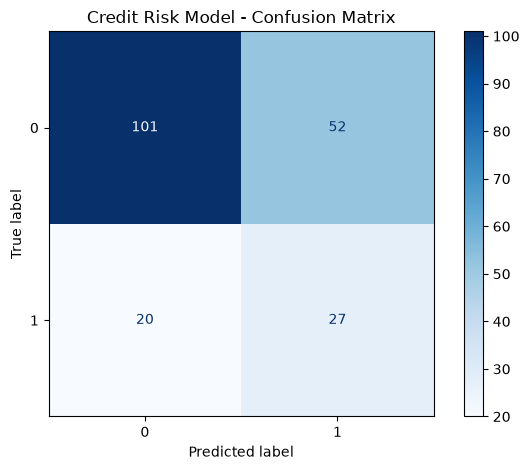


--- Fraud Detection Model ---
Accuracy:  0.995
Precision: 0.000
Recall:    0.000
F1 Score:  0.000

Confusion Matrix:
[[1989    0]
 [  11    0]]


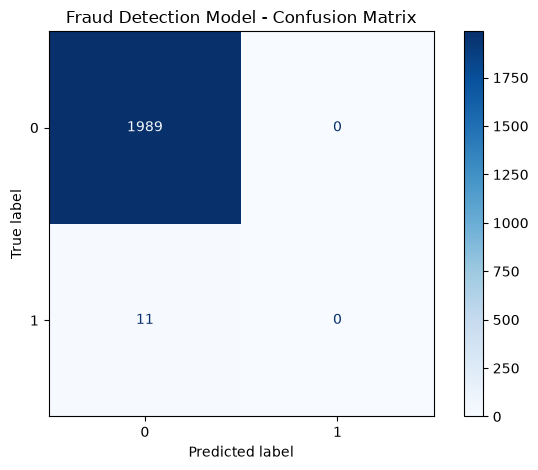

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Make sure the models predict on their test data
risk_predictions = risk_model.predict(X_test)
fraud_predictions = fraud_model.predict(X_test_fraud)

# Print evaluation scores
def show_scores(name, actual, predicted):
    print(f"\n--- {name} ---")
    print(f"Accuracy:  {accuracy_score(actual, predicted):.3f}")
    print(f"Precision: {precision_score(actual, predicted, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(actual, predicted, zero_division=0):.3f}")
    print(f"F1 Score:  {f1_score(actual, predicted, zero_division=0):.3f}")

    matrix = confusion_matrix(actual, predicted)
    print("\nConfusion Matrix:")
    print(matrix)

    ConfusionMatrixDisplay(confusion_matrix=matrix).plot(cmap="Blues")
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

# Credit Risk: 0 = Good credit, 1 = Bad credit
show_scores("Credit Risk Model", y_test, risk_predictions)

# Fraud: 0 = Not Fraud, 1 = Fraud
show_scores("Fraud Detection Model", y_test_fraud, fraud_predictions)

In [56]:
import pandas as pd

evaluation_results = pd.DataFrame([
    {
        "Model": "Credit Risk",
        "Accuracy": accuracy_score(y_test, risk_predictions),
        "Precision": precision_score(y_test, risk_predictions, zero_division=0),
        "Recall": recall_score(y_test, risk_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, risk_predictions, zero_division=0)
    },
    {
        "Model": "Fraud Detection",
        "Accuracy": accuracy_score(y_test_fraud, fraud_predictions),
        "Precision": precision_score(y_test_fraud, fraud_predictions, zero_division=0),
        "Recall": recall_score(y_test_fraud, fraud_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_fraud, fraud_predictions, zero_division=0)
    }
])

display(evaluation_results.round(3))
evaluation_results.to_csv("model_evaluation_results.csv", index=False)

print("Saved: model_evaluation_results.csv")

,Model,Accuracy,Precision,Recall,F1 Score
0,Credit Risk,0.640,0.342,0.574,0.429
1,Fraud Detection,0.994,0.000,0.000,0.000


Saved: model_evaluation_results.csv
